# 1 — Feasibility Test & Preliminary Data Exploration

> **Note.** This notebook is a preliminary, exploratory stage, kept for **provenance only**; its numbers do **not** feed the thesis results. It has two parts:
>
> 1. **Exploratory data analysis** of the six selected stocks (MSFT, JNJ, PG, XOM, JPM, NVDA) on 5-minute realized variance — summary statistics, time series, distributions, autocorrelation, and cross-stock correlation.
> 2. A single-stock **feasibility test** (MSFT only, an earlier 2023-01-01 split, and an ad-hoc feature set) that confirmed the GARCH-vs-ML comparison was technically workable before scaling up.
>
> The definitive analysis lives in notebooks 2–4 (`2_feature_engineering` → `3_forecasts` → `4_outputs`), which use all six stocks, the 2022-01-01 split, the finalized feature sets, and the full six-model comparison.

In [1]:
# Load packages
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from config import *   

In [2]:
# Load raw VOLARE data, filter to the six selected stocks (config `stocks`),
# and build the base features used throughout the EDA below.
df = pd.read_csv('../data/raw/realized_var_stocks.csv')
df['date'] = pd.to_datetime(df['date'])
df = df[df['symbol'].isin(stocks)].copy()

df['rv']     = df['rv5']
df['log_rv'] = np.log(df['rv'])
df['ret']    = 100 * df['close_price'].apply(np.log).diff()
df.head()

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss,index,rv,log_rv,ret
50886,2015-01-02,JNJ,stocks,5572545,37840,105.0566,104.596,105.55,104.13,0.000066,...,0.000080,0.000068,0.000097,4.814808e-08,1.428697e-08,1.622797e-08,"DOW30, S&P100",0.000092,-9.290984,NaN
50887,2015-01-05,JNJ,stocks,7552217,57590,104.4800,103.770,104.74,103.68,0.000037,...,0.000084,0.000068,0.000090,1.996216e-08,5.496678e-09,6.938898e-09,"DOW30, S&P100",0.000077,-9.469729,-0.792840
50888,2015-01-06,JNJ,stocks,7305273,57291,104.3267,103.280,104.98,102.94,0.000139,...,0.000157,0.000111,0.000145,5.208954e-08,2.075676e-08,1.515296e-08,"DOW30, S&P100",0.000147,-8.823249,-0.473317
50889,2015-01-07,JNJ,stocks,7902234,56136,103.9100,105.560,105.83,103.81,0.000134,...,0.000071,0.000079,0.000102,2.482234e-08,2.989271e-08,1.968627e-08,"DOW30, S&P100",0.000107,-9.141570,2.183577
50890,2015-01-08,JNJ,stocks,9529166,58955,105.9845,106.390,106.49,105.75,0.000018,...,0.000055,0.000061,0.000073,2.855343e-08,3.435138e-09,5.918351e-09,"DOW30, S&P100",0.000049,-9.916692,0.783208


## Part 1 — Exploratory Data Analysis (six stocks)

Summary statistics, time-series, distributions, autocorrelation, and cross-stock correlation for the six selected stocks. Figures render inline only — they are **not** written to disk, so `results/` holds thesis outputs only.

In [3]:
# Summary statistics across stocks

from scipy.stats import kurtosis
from scipy.stats import jarque_bera

# define custom helper functions
def q25(x):                             # first quartile
    return x.quantile(0.25)

def q75(x):                             # third quartile
    return x.quantile(0.75)

def skewness(x):                        # measure asymmetry
    return x.skew()

def jb_stat(x):                         # return jb test statistic
    return jarque_bera(x)[0]

def jb_pvalue(x):                       # extract the jb test p-value
    return jarque_bera(x)[1]

summary = df.groupby('symbol').agg(
    Obs=('log_rv', 'count'),
    Mean=('log_rv', 'mean'),
    Std_Dev=('log_rv', 'std'),
    Min=('log_rv', 'min'),
    Q25=('log_rv', q25),
    Median=('log_rv', 'median'),
    Q75=('log_rv', q75),
    Max=('log_rv', 'max'),
    Skewness=('log_rv', skewness),
    # scipy's kurtosis defaults to fisher=True, i.e. EXCESS kurtosis (0 under normality)
    Excess_Kurtosis=('log_rv', kurtosis),
    Jarque_Bera=('log_rv', jb_stat),
    P_value=('log_rv', jb_pvalue),
).reset_index()

summary = summary.round(2)

print("Table: Summary Statistics for Log_RV by stock\n")
print(summary.to_markdown(index=False))

Table: Summary Statistics for Log_RV by stock

| symbol   |   Obs |   Mean |   Std_Dev |    Min |    Q25 |   Median |   Q75 |   Max |   Skewness |   Excess_Kurtosis |   Jarque_Bera |   P_value |
|:---------|------:|-------:|----------:|-------:|-------:|---------:|------:|------:|-----------:|------------------:|--------------:|----------:|
| JNJ      |  2827 |  -9.5  |      0.75 | -11.55 |  -9.98 |    -9.57 | -9.1  | -4.05 |       1.11 |              3.93 |       2405.88 |         0 |
| JPM      |  2827 |  -9.04 |      0.79 | -11.74 |  -9.58 |    -9.11 | -8.59 | -4.87 |       0.87 |              2.13 |        889.95 |         0 |
| MSFT     |  2827 |  -9.02 |      0.85 | -11.76 |  -9.59 |    -9.09 | -8.53 | -5.02 |       0.75 |              1.57 |        554.84 |         0 |
| NVDA     |  2827 |  -7.9  |      0.82 | -10.41 |  -8.49 |    -7.97 | -7.37 | -4.44 |       0.51 |              0.31 |        132.27 |         0 |
| PG       |  2827 |  -9.53 |      0.74 | -11.31 | -10.01 |    -9

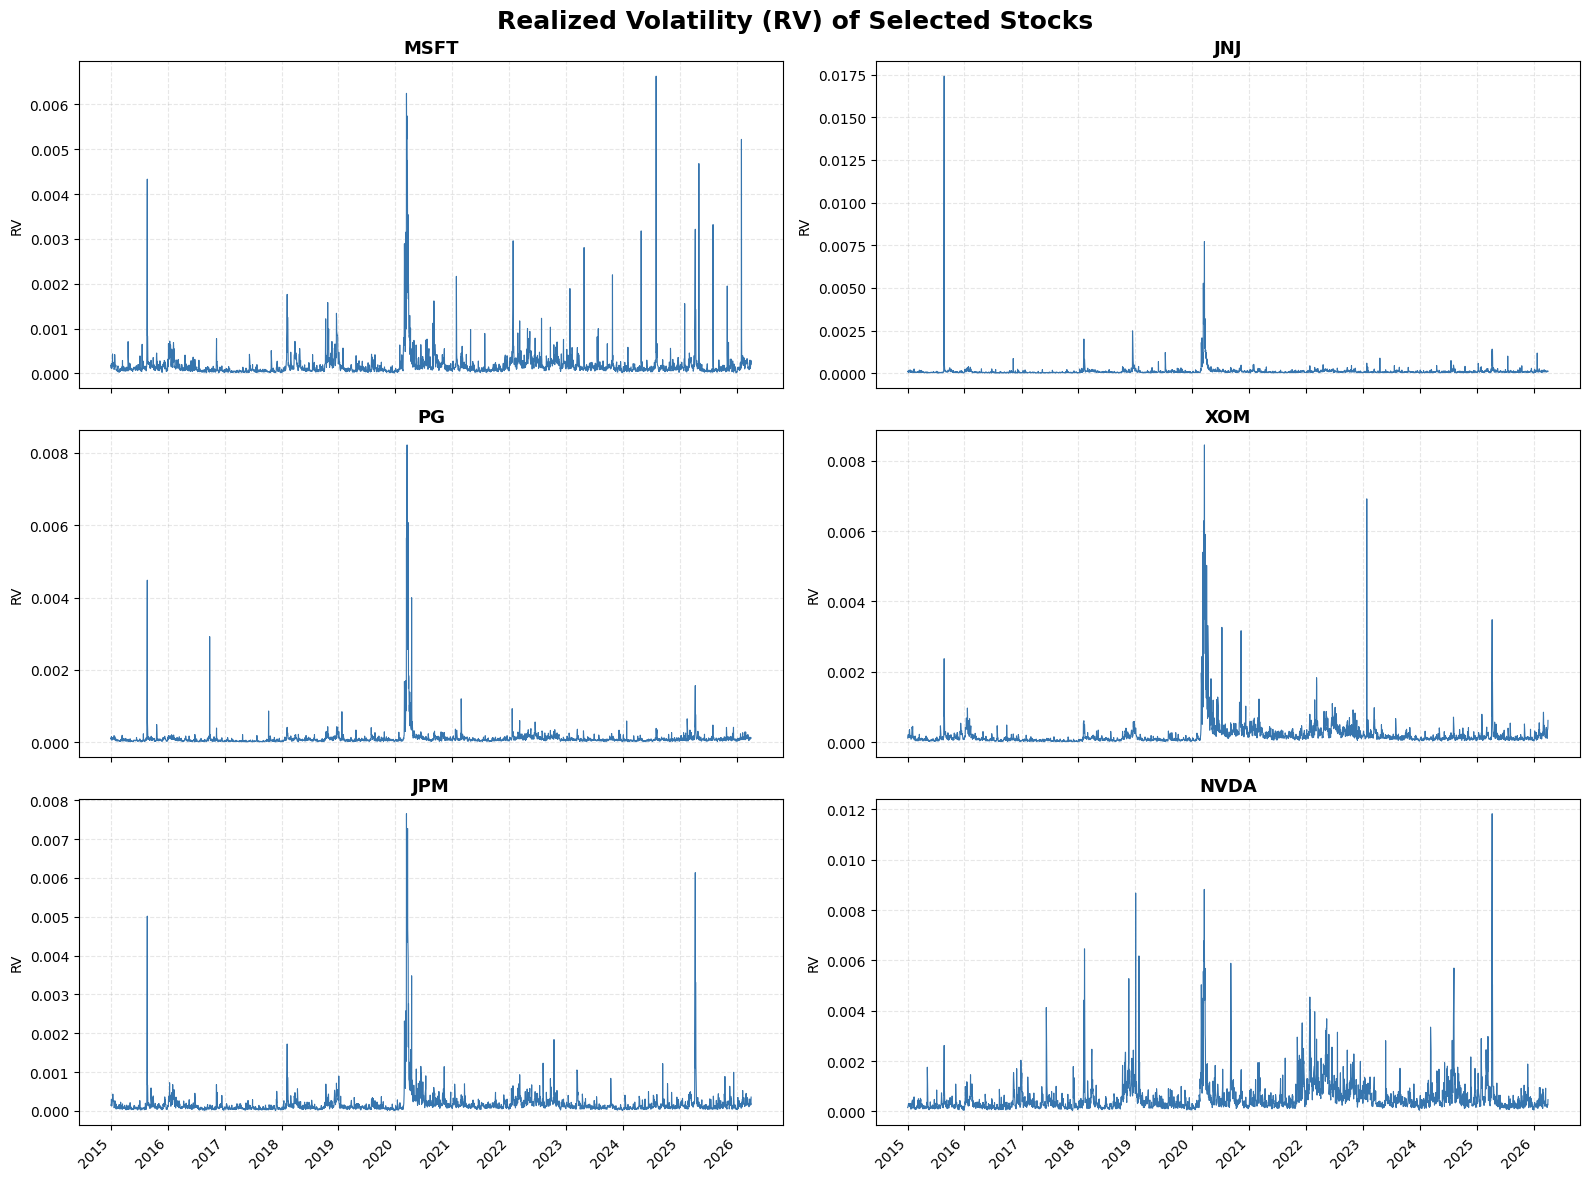

In [4]:
# Time-series plot of rv across stocks

# create subplot grid
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True,)

# flatten axes array for easier iteration
axes = axes.flatten()

# loop through stocks
for ax, stock in zip(axes, stocks):

    # filter stock
    stock_df = df[df['symbol'] == stock]

    # plot
    ax.plot(
        stock_df['date'],
        stock_df['rv'],
        linewidth=0.8,
        color="#2E6FABF5"
    )

    # title
    ax.set_title(
        f"{stock}",
        fontsize=13,
        fontweight='bold'
    )

    # label
    ax.set_ylabel("RV")

    # format x-axis
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # grid
    ax.grid(
        True,
        alpha=0.3,
        linestyle='--'
    )

# overall figure title
fig.suptitle(
    "Realized Volatility (RV) of Selected Stocks",
    fontsize=18,
    fontweight='bold',
    y=0.98
)

# rotate dates
fig.autofmt_xdate(rotation=45)

# improve spacing
plt.tight_layout()

plt.show()

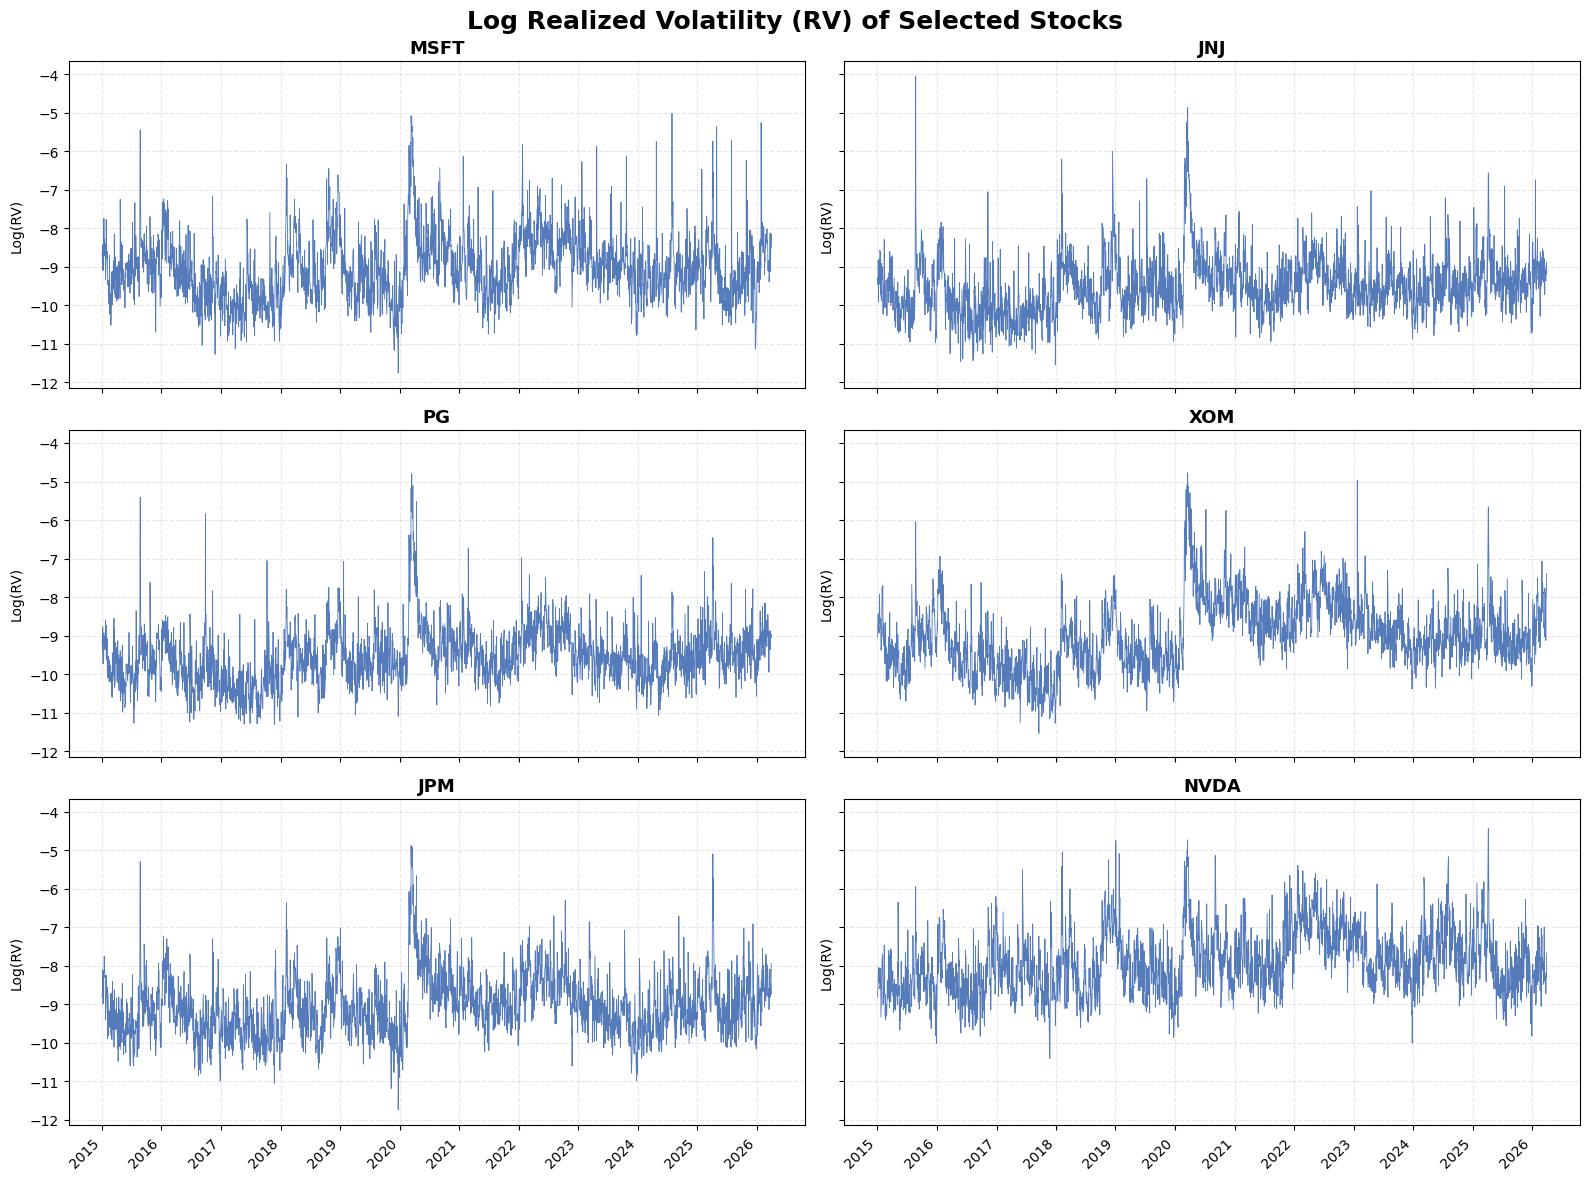

In [5]:
# Time series plot of log(rv) across stocks

# create subplot grid
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 12),
    sharex=True,
    sharey=True
)

# flatten axes array for easier iteration
axes = axes.flatten()

# loop through stocks
for ax, stock in zip(axes, stocks):

    # filter stock
    df_stock = df[df['symbol'] == stock]

    # plot
    ax.plot(
        df_stock['date'],
        df_stock['log_rv'],
        linewidth=0.6,
        color="#2E5CABCF"
    )

    # title
    ax.set_title(
        f"{stock}",
        fontsize=13,
        fontweight='bold'
    )

    # label
    ax.set_ylabel("Log(RV)")

    # format x-axis
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # grid
    ax.grid(
        True,
        alpha=0.3,
        linestyle='--'
    )

# overall figure title
fig.suptitle(
    "Log Realized Volatility (RV) of Selected Stocks",
    fontsize=18,
    fontweight='bold',
    y=0.98
)

# rotate dates
fig.autofmt_xdate(rotation=45)

# improve spacing
plt.tight_layout()

plt.show()

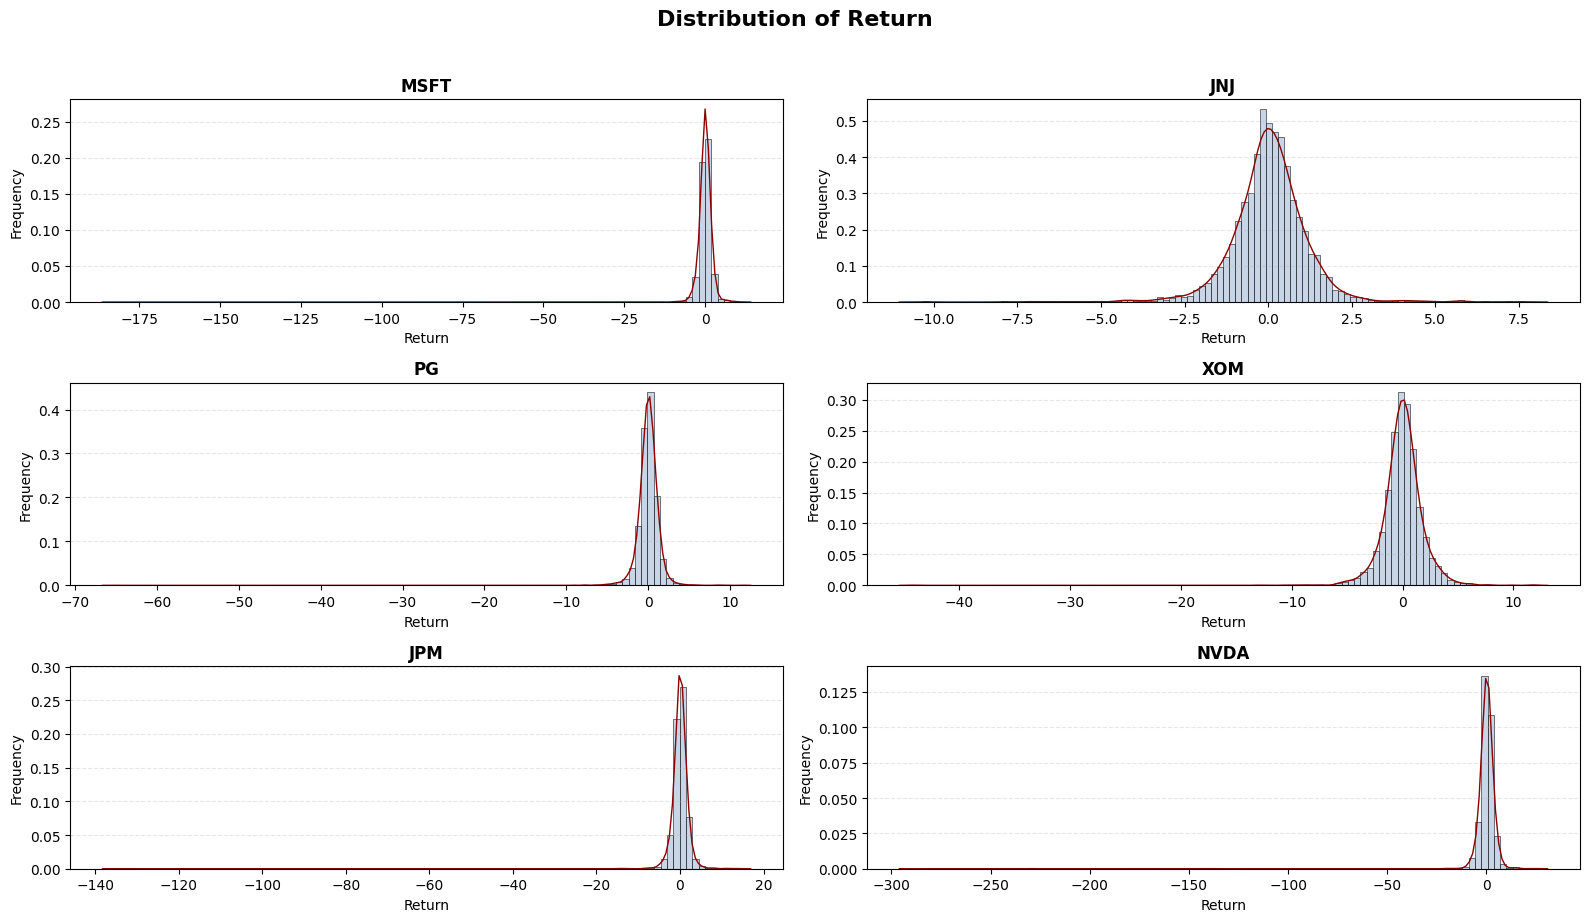

In [6]:
# Histogram plot of return across stocks

fig, ax = plt.subplots(3, 2, figsize=(16, 9))
ax = ax.flatten()

for idx, stock in enumerate(stocks):

    df_stock = df[df['symbol'] == stock]

    # histogram
    sns.histplot(
        data=df_stock,
        x='ret',
        bins=100,
        color='lightsteelblue',                                      
        edgecolor='black',
        stat='density',
        alpha=0.7,
        ax=ax[idx]
    )

    # kde line
    sns.kdeplot(
        data=df_stock,
        x='ret',
        color='darkred',
        linewidth=1,
        ax=ax[idx]
    )   
    
    ax[idx].set_title(
        f'{stock}',
        fontsize=12,
        fontweight='bold'
    )

    ax[idx].set_xlabel('Return')
    ax[idx].set_ylabel('Frequency')
    ax[idx].grid(axis='y', alpha=0.3, linestyle='--')

plt.suptitle(
    'Distribution of Return',
    fontsize=16,
    fontweight='bold',
    y=1.02)

plt.tight_layout()

plt.show()

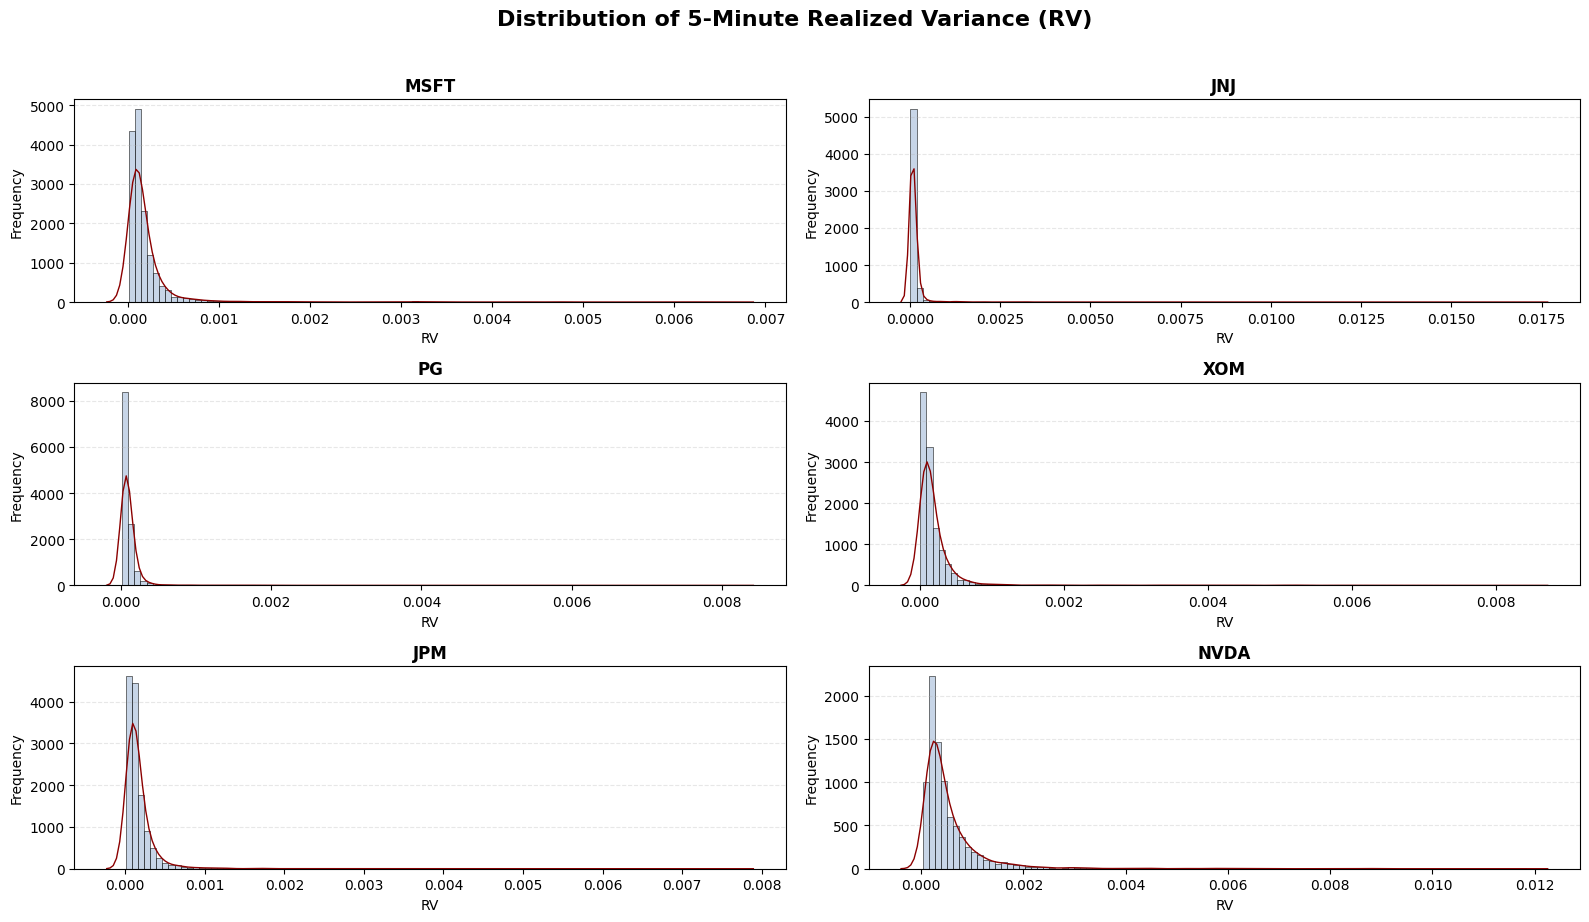

In [7]:
# Histogram plot of rv across stocks

fig, ax = plt.subplots(3, 2, figsize=(16, 9))
ax = ax.flatten()

for idx, stock in enumerate(stocks):

    df_stock = df[df['symbol'] == stock]

    # histogram
    sns.histplot(
        data=df_stock,
        x='rv',
        bins=100,
        color='lightsteelblue',                                      
        edgecolor='black',
        stat='density',
        alpha=0.7,
        ax=ax[idx]
    )

    # kde line
    sns.kdeplot(
        data=df_stock,
        x='rv',
        color='darkred',
        linewidth=1,
        ax=ax[idx]
    )   
    
    ax[idx].set_title(
        f'{stock}',
        fontsize=12,
        fontweight='bold'
    )

    ax[idx].set_xlabel('RV')
    ax[idx].set_ylabel('Frequency')
    ax[idx].grid(axis='y', alpha=0.3, linestyle='--')

plt.suptitle(
    'Distribution of 5-Minute Realized Variance (RV)',
    fontsize=16,
    fontweight='bold',
    y=1.02)

plt.tight_layout()

plt.show()

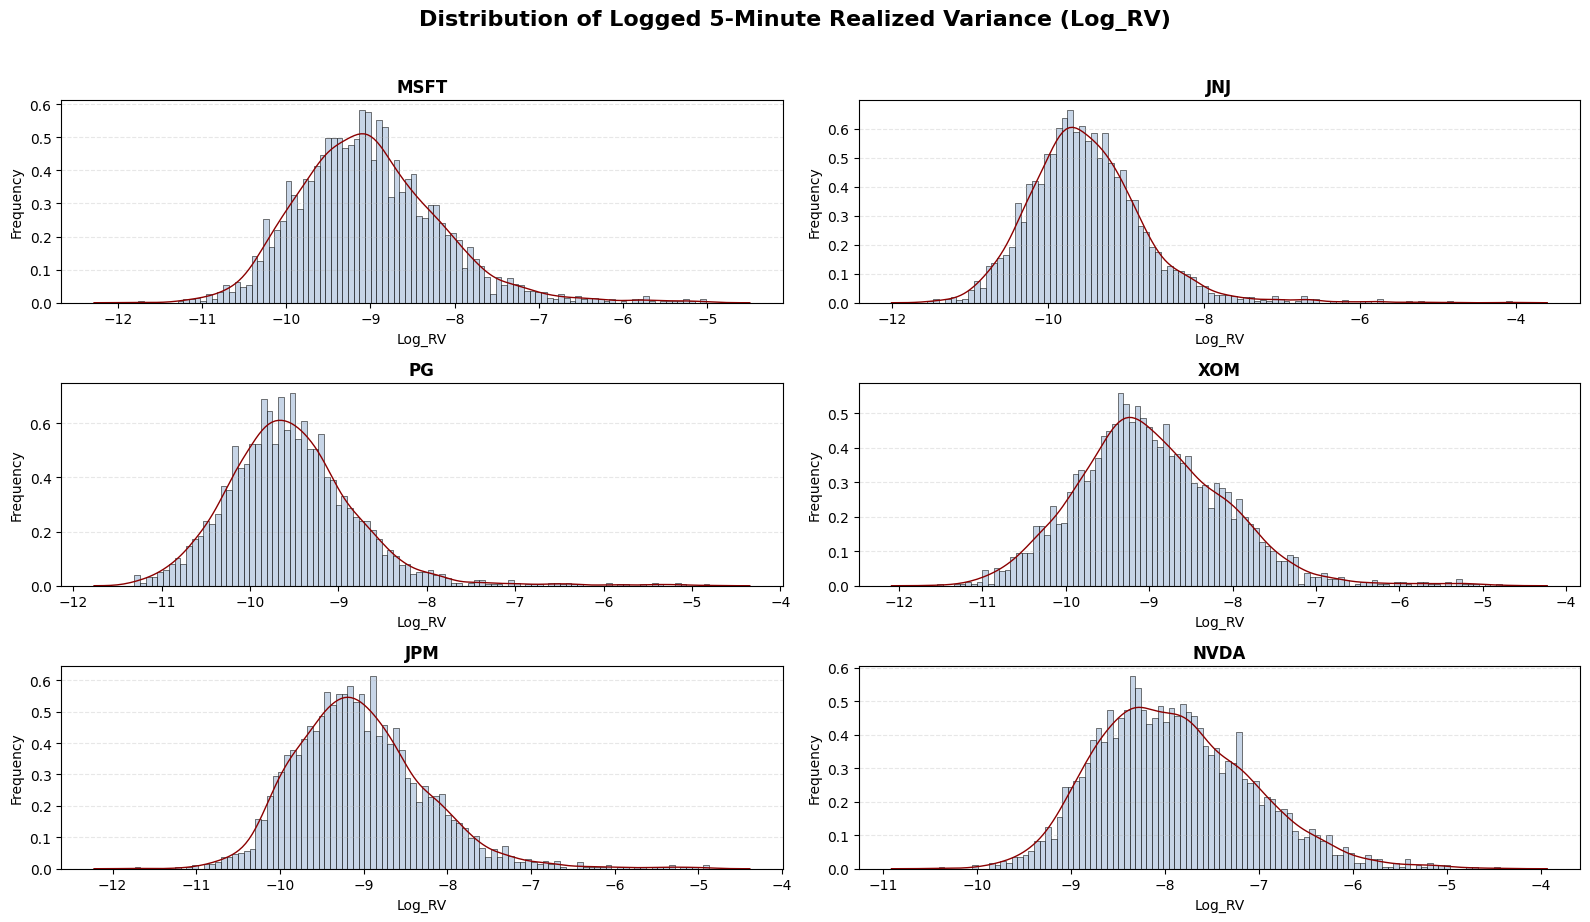

In [8]:
# Histogram plot of log_rv across stocks

fig, ax = plt.subplots(3, 2, figsize=(16, 9))
ax = ax.flatten()

for idx, stock in enumerate(stocks):

    df_stock = df[df['symbol'] == stock]

    # histogram
    sns.histplot(
        data=df_stock,
        x='log_rv',
        bins=100,
        color='lightsteelblue',                                      
        edgecolor='black',
        stat='density',
        alpha=0.7,                
        ax=ax[idx]
    )

    # kde line
    sns.kdeplot(
        data=df_stock,
        x='log_rv',
        color='darkred',
        linewidth=1,
        ax=ax[idx]
    )   
    
    ax[idx].set_title(
        f'{stock}',
        fontsize=12,
        fontweight='bold'
    )

    ax[idx].set_xlabel('Log_RV')
    ax[idx].set_ylabel('Frequency')
    ax[idx].grid(axis='y', alpha=0.3, linestyle='--')

plt.suptitle(
    'Distribution of Logged 5-Minute Realized Variance (Log_RV)',
    fontsize=16,
    fontweight='bold',
    y=1.02)

plt.tight_layout()

plt.show()

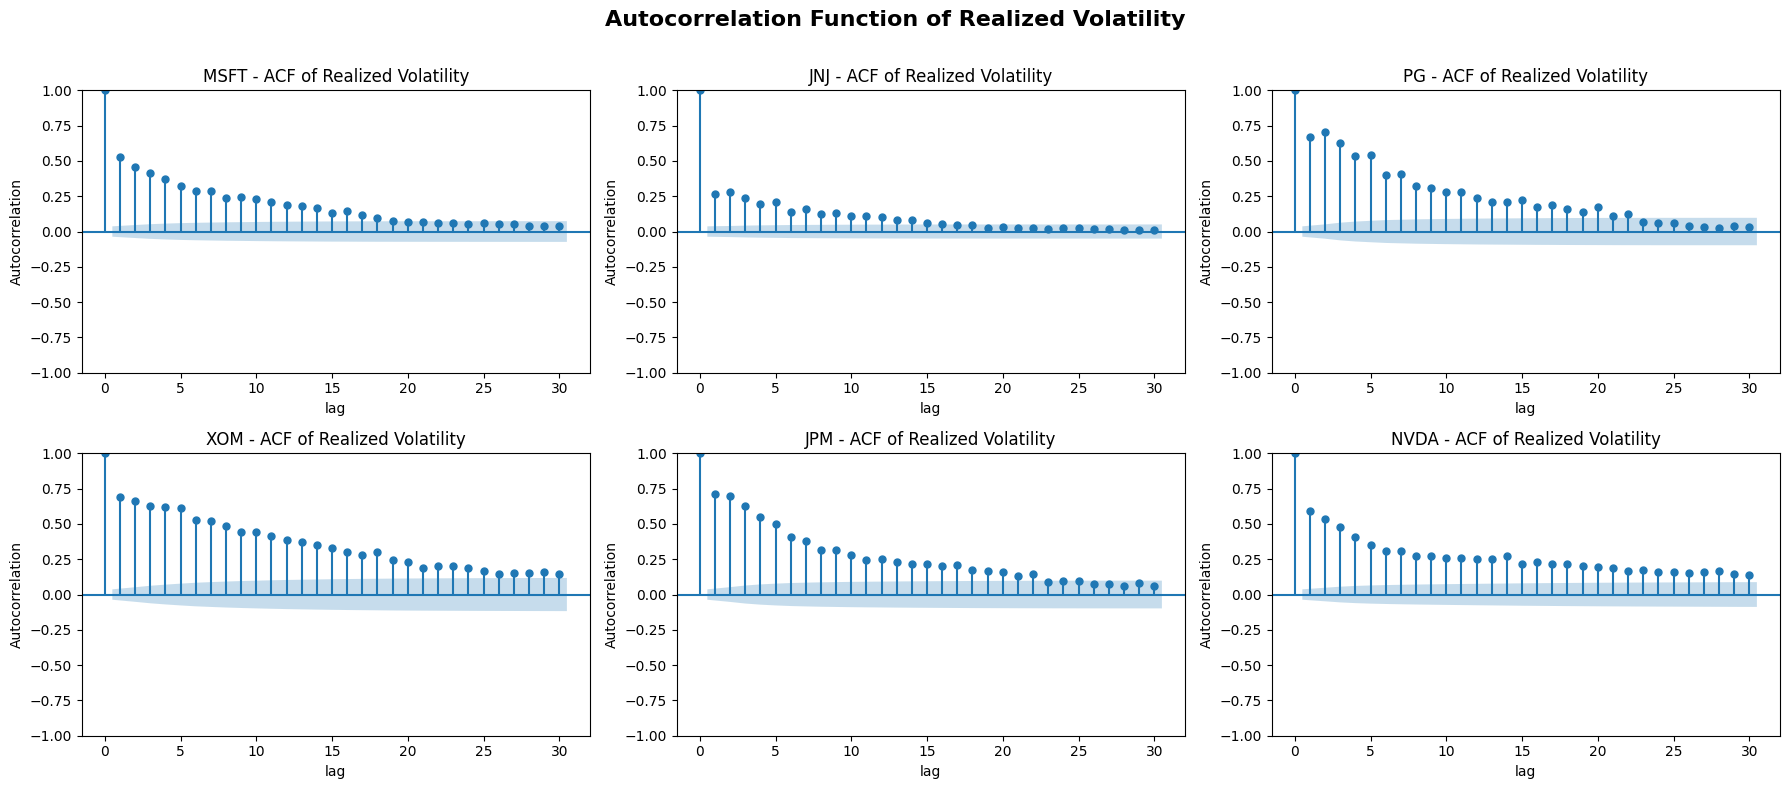

In [9]:
# Autocorrelation functions (ACF) of rv across stocks
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for idx, stock in enumerate(stocks):
    
    df_stock = df[df['symbol'] == stock]

    plot_acf(
        df_stock['rv'],
        lags=30,
        alpha=0.05,               # 95% confidence intervals
        ax=axes[idx],
    )
    
    axes[idx].set_title(f'{stock} - ACF of Realized Volatility')
    axes[idx].set_xlabel('lag')
    axes[idx].set_ylabel('Autocorrelation')

plt.suptitle(
    'Autocorrelation Function of Realized Volatility', 
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=(0, 0, 1, 0.97))

plt.show()

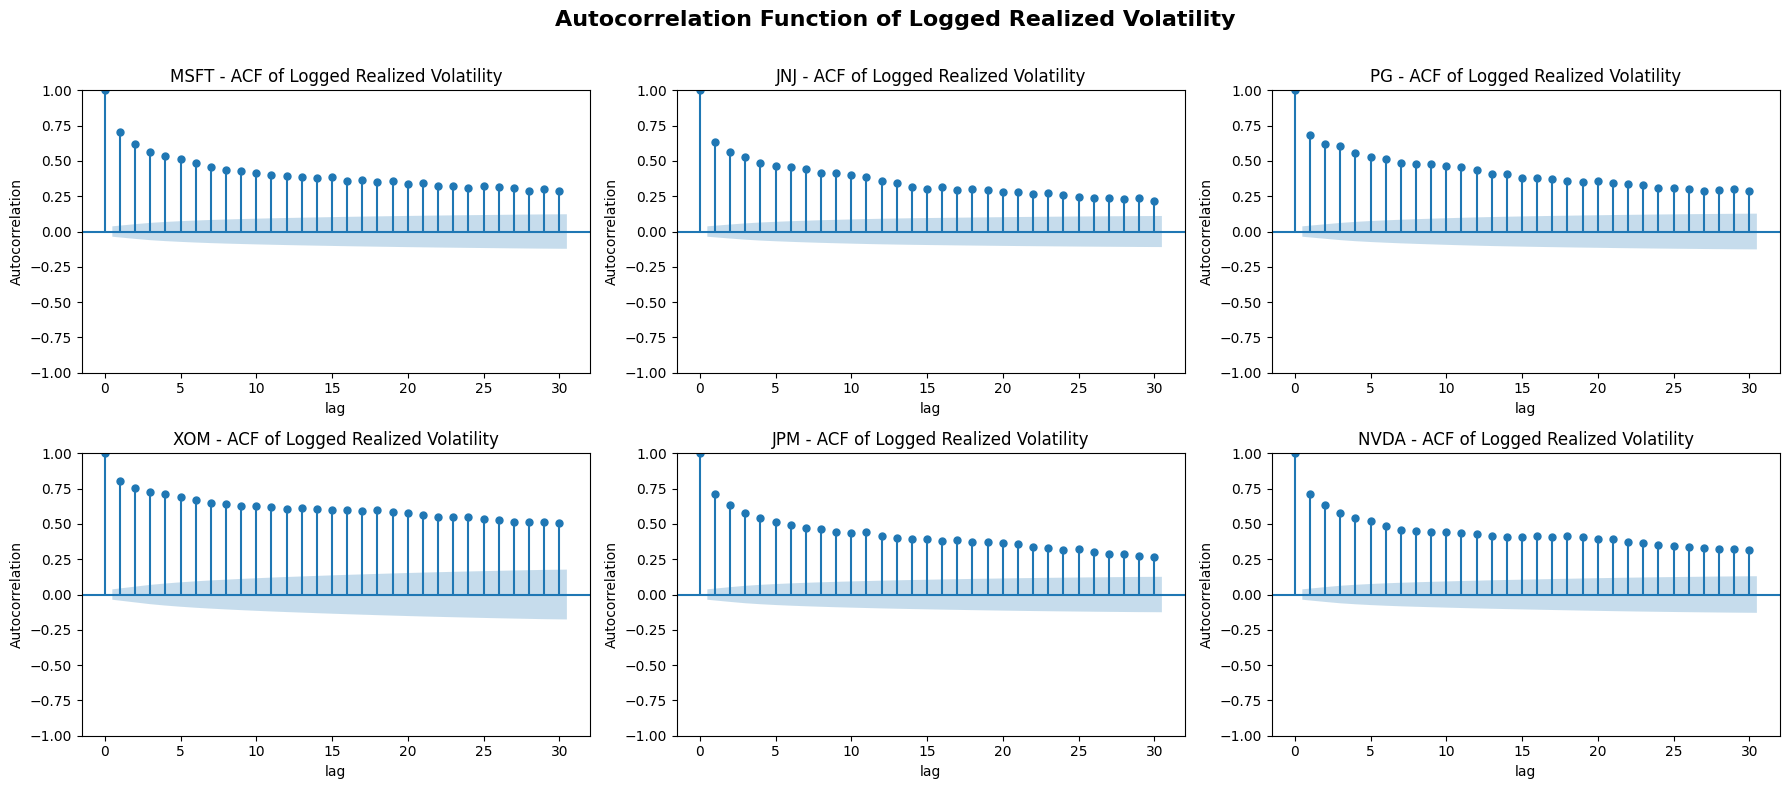

In [10]:
# Autocorrelation functions (ACF) of log(rv) across stocks
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for idx, stock in enumerate(stocks):
    
    df_stock = df[df['symbol'] == stock]

    plot_acf(
        df_stock['log_rv'],
        lags=30,
        alpha=0.05,               # 95% confidence intervals
        ax=axes[idx]
    )
    
    axes[idx].set_title(f'{stock} - ACF of Logged Realized Volatility')
    axes[idx].set_xlabel('lag')
    axes[idx].set_ylabel('Autocorrelation')

plt.suptitle(
    'Autocorrelation Function of Logged Realized Volatility', 
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=(0, 0, 1, 0.97))

plt.show()

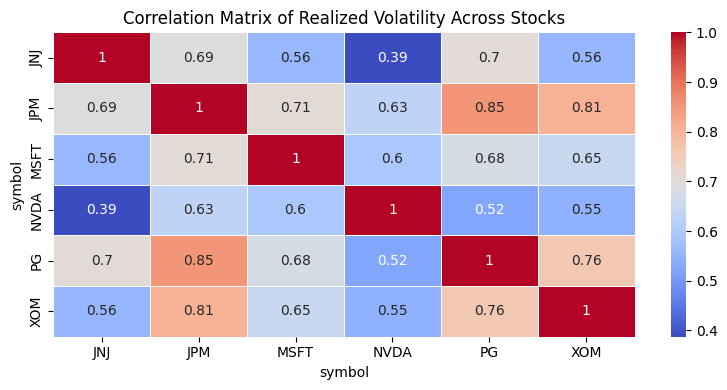

In [11]:
# Cross-stock realized volatility dependence

# pivot rv data
pivot = df.pivot(
    index='date',
    columns='symbol',
    values='rv'
)

# correlation matrix
corr_matrix = pivot.corr()

# plot heatmap
plt.figure(figsize=(8,4))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5   
)

plt.title('Correlation Matrix of Realized Volatility Across Stocks')

plt.tight_layout()

plt.show()

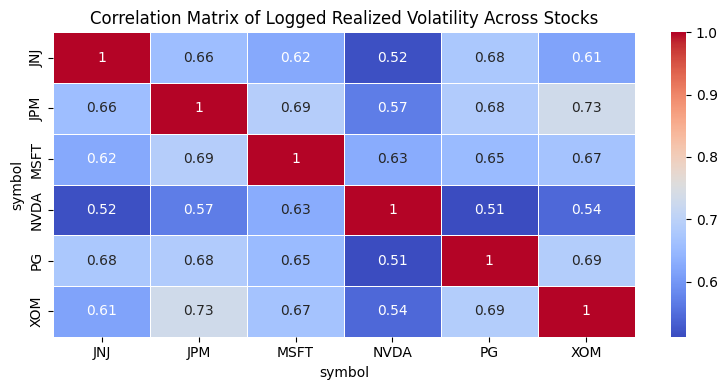

In [12]:
# Cross-stock logged realized volatility dependence

pivot = df.pivot(
    index='date',
    columns='symbol',
    values='log_rv'
)

corr_matrix = pivot.corr()

plt.figure(figsize=(8,4))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5   
)

plt.title('Correlation Matrix of Logged Realized Volatility Across Stocks')

plt.tight_layout()

plt.show()

## Part 2 — Single-Stock Feasibility Test (MSFT)

A preliminary GARCH(1,1)-vs-XGBoost proof-of-concept on MSFT alone, using an earlier 2023-01-01 split and an ad-hoc lagged-feature set. This section only establishes technical feasibility; the finalized six-model, six-stock comparison is in notebooks 2–4.

In [13]:
# Feature engineering - use Microsoft only to test thesis feasibility
df_2 = df[df['symbol'] == 'MSFT'].copy()

# get return - scaled * 100 for numerical stability
df_2['return'] = 100 * df_2['close_price'].apply(np.log).diff()
df_2.head()

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,minrv5_ss,rk,rq1,rq5,rq5_ss,index,rv,log_rv,ret,return
70675,2015-01-02,MSFT,stocks,27165433,112220,46.66,46.7100,47.420,46.5400,0.000127,...,0.000152,0.000167,5.988654e-08,1.517170e-07,8.806290e-08,"DOW30, S&P100",0.000180,-8.625160,-184.016556,NaN
70676,2015-01-05,MSFT,stocks,38639787,157838,46.37,46.3100,46.730,46.2500,0.000038,...,0.000113,0.000121,3.701053e-08,1.825033e-08,1.755052e-08,"DOW30, S&P100",0.000116,-9.059084,-0.860035,-0.860035
70677,2015-01-06,MSFT,stocks,35433167,173570,46.38,45.6500,46.749,45.5400,0.000248,...,0.000193,0.000206,5.515479e-08,4.305021e-08,5.505600e-08,"DOW30, S&P100",0.000217,-8.436778,-1.435431,-1.435431
70678,2015-01-07,MSFT,stocks,28676608,140188,45.98,46.2492,46.460,45.4982,0.000158,...,0.000196,0.000190,1.138118e-07,3.227680e-08,4.712660e-08,"DOW30, S&P100",0.000176,-8.644931,1.304056,1.304056
70679,2015-01-08,MSFT,stocks,28688530,142365,46.81,47.5900,47.750,46.7500,0.000162,...,0.000121,0.000124,2.322807e-08,1.549031e-08,1.494879e-08,"DOW30, S&P100",0.000111,-9.102140,2.857849,2.857849


In [14]:
# lagged features from 'return' and 'rv5' to capture momentum
for lag in [1,3,5]:
    df_2[f'ret_lag_{lag}'] = df_2['return'].shift(lag) # avoid look-ahead bias
    df_2[f'rv_lag_{lag}'] = df_2['rv5'].shift(lag)

# create two rolling volatility features to see the persistence of 'rv5'
df_2['rv_5'] = df_2['rv5'].rolling(5).mean().shift(1) # avoid data leakage
df_2['rv_22'] = df_2['rv5'].rolling(22).mean().shift(1)

df_2 = df_2.dropna() # drop the missing values due to rolling
df_2.head()

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,ret,return,ret_lag_1,rv_lag_1,ret_lag_3,rv_lag_3,ret_lag_5,rv_lag_5,rv_5,rv_22
70697,2015-02-04,MSFT,stocks,40835761,158482,41.9375,41.830,42.2100,41.360,0.000149,...,0.816135,0.816135,0.555893,0.000183,-3.686159,0.000154,-3.577772,0.000281,0.000200,0.000197
70698,2015-02-05,MSFT,stocks,36219983,160993,42.2164,42.430,42.6400,41.852,0.000125,...,1.424187,1.424187,0.816135,0.000135,1.908548,0.000152,1.971692,0.000232,0.000171,0.000195
70699,2015-02-06,MSFT,stocks,34100561,146484,42.6800,42.400,42.7894,42.150,0.000082,...,-0.070730,-0.070730,1.424187,0.000077,0.555893,0.000183,-3.686159,0.000154,0.000140,0.000193
70700,2015-02-09,MSFT,stocks,27273552,119877,42.2400,42.360,42.7400,42.200,0.000058,...,-0.094384,-0.094384,-0.070730,0.000085,0.816135,0.000135,1.908548,0.000152,0.000126,0.000187
70701,2015-02-10,MSFT,stocks,29260824,116665,42.7400,42.602,42.7700,42.180,0.000070,...,0.569668,0.569668,-0.094384,0.000088,1.424187,0.000077,0.555893,0.000183,0.000114,0.000183


In [15]:
# Split dataset for training and testing
split_date = pd.to_datetime('2023-01-01')
train = df_2[df_2['date'] < split_date]
test = df_2[df_2['date'] >= split_date]

In [16]:
# Garch(1,1) rolling forecast
from arch import arch_model

# define a rolling garch function
def rolling_garch(train_returns, test_returns):
    preds = []
    rolling_returns = train_returns.copy()

    for t in range(len(test_returns)):
        model = arch_model(rolling_returns, vol="GARCH", p=1, q=1)
        res = model.fit(disp="off")

        forecast = res.forecast(horizon=1) # predict one-period ahead
        var_pred = forecast.variance.values[-1, 0] # extract predicted variance

        preds.append(var_pred) # add the predicted values into the list

        # expanding window rolling
        rolling_returns = pd.concat([rolling_returns, test_returns.iloc[t:t+1]]) 

    return np.array(preds)

# run the prediction
rolling_garch_preds = rolling_garch(train['return'], test['return'])
rolling_garch_preds = rolling_garch_preds / (100**2) # rescale back to ensure the same-level comparison

In [17]:
# XGBoost rolling forecast
from xgboost import XGBRegressor

# select features for modeling
features = [col for col in df_2.columns if 'lag' in col or 'rv_' in col ] 

def rolling_xgb(train_df, test_df, features, target, retrain_freq=20): 

    preds = []
    train_data = train_df.copy()

     # 1, initial training - use the designated parameter to reduce overfitting risk
    model = XGBRegressor(  
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8
    )

    model.fit(train_data[features], train_data[target])
    

    # 2, start to roll
    for i in range(len(test_df)):

        # a, predict one-period ahead
        x_input = test_df[features].iloc[i:i+1]
        pred = model.predict(x_input)[0]
        preds.append(pred)

        # b, expand training set
        train_data = pd.concat([train_data, test_df.iloc[i:i+1]])

        # c, retrain the model every 20 days using updated data to balance the computational cost to regime shift
        if (i+1) % retrain_freq == 0:
            model = XGBRegressor(
                n_estimators=100,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8
            )
            
            model.fit(train_data[features],
                      train_data[target])

    return np.array(preds)

# run the prediction
rolling_xgb_preds = rolling_xgb(train, test, features, "rv5")

In [18]:
# Models evaluation

# def MSE and QLike function using their formula
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def qlike(y_true, y_pred):
    return np.mean((y_true/y_pred) - np.log(y_true/y_pred) - 1)

# build a dataframe to store the comparison results of 2 models
results = pd.DataFrame({
    'Models': ['GARCH(1,1)', 'XGBoost'],
    'MSE': [
        mse(test['rv5'].values, rolling_garch_preds),
        mse(test['rv5'].values, rolling_xgb_preds)
        ],
    'QLIKE':[
        qlike(test['rv5'].values, rolling_garch_preds),
        qlike(test['rv5'].values, rolling_xgb_preds)
    ]
})

print(results)

       Models           MSE     QLIKE
0  GARCH(1,1)  2.089324e-07  0.429406
1     XGBoost  1.816716e-07  0.403166


The comparison table above shows that XGBoost achieves slightly lower forecast error on both evaluation metrics. The 13% reduction in Mean Squared Error (MSE) indicates that, on average, XGBoost's predictions deviate less from realized volatility in absolute terms. The 6% improvement in QLIKE suggests better calibration of the forecast distribution, particularly during extreme volatility episodes. This provides preliminary evidence that ML models may offer incremental predictive value, and motivates the full comparative study across diverse stocks, models, and horizons.

Note: since only one stock is used to test feasibility, the MCS test is not conducted here.

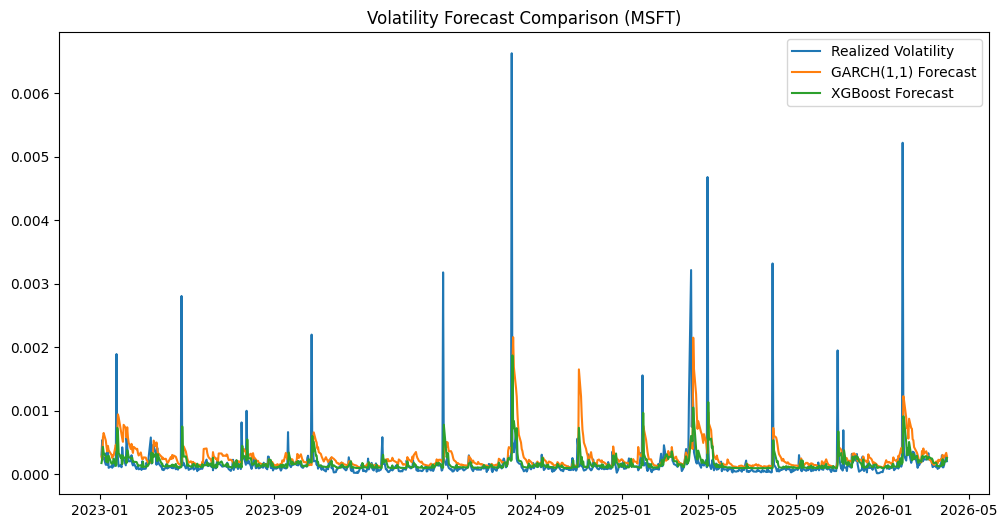

In [19]:
# Visualize predicted volatility against the actual series

plt.figure(figsize=(12,6))

plt.plot(test['date'], test['rv5'], label='Realized Volatility')
plt.plot(test['date'], rolling_garch_preds, label='GARCH(1,1) Forecast')
plt.plot(test['date'], rolling_xgb_preds, label='XGBoost Forecast')

plt.legend()
plt.title('Volatility Forecast Comparison (MSFT)')
plt.show()

**Out-of-Sample Volatility Forecast Comparison (MSFT, 2023–2026)**

The figure plots the daily realized volatility (blue) against the 1-day-ahead forecasts of GARCH(1,1) (orange) and XGBoost (green) over the out-of-sample test period (2023–2026), showing how each model responds to regime shifts and volatility clusters.

Both models capture the baseline volatility level and the broad clustering pattern. XGBoost tracks the realized series slightly more closely overall — consistent with its modestly lower MSE and QLIKE — and fits the calm periods particularly well. During sharp volatility spikes both models react with a short lag rather than anticipating the jump, so neither traces the steepest ascents precisely. This single-stock exercise only establishes feasibility; the full multi-horizon, six-model comparison is carried out in notebooks 2–4.